# Optimizing within clusters before combining them

The spectral condition number compares the largest and smallest eigenvalues of a positive definite covariance matrix:

$$
\kappa_2(\Sigma)=\frac{\lambda_{\max}(\Sigma)}{\lambda_{\min}(\Sigma)}.
$$

Here, $\Sigma$ is a covariance matrix, $\lambda_{\max}(\Sigma)$ and $\lambda_{\min}(\Sigma)$ are its largest and smallest eigenvalues, and $\kappa_2(\Sigma)$ measures how strongly small input changes can be magnified by inversion.

,Field,Value
0,Provider,Kenneth R. French Data Library
1,Return type,Daily value-weighted return
2,Analysis start,2019-01-02
3,Analysis end,2025-12-31
4,Complete dates,1760
5,Selected industries,16
6,Selection rule,"First 16 industries in archive order, fixed be..."


,Case,Assets,Smallest eigenvalue,Largest eigenvalue,Condition number,Mean off-diagonal correlation
0,Separated clusters,6,0.003459,0.09364,27.072265,0.28
1,Connected clusters,6,0.003456,0.099277,28.727151,0.43
2,Public industries,16,0.00576,0.595064,103.308892,0.532016


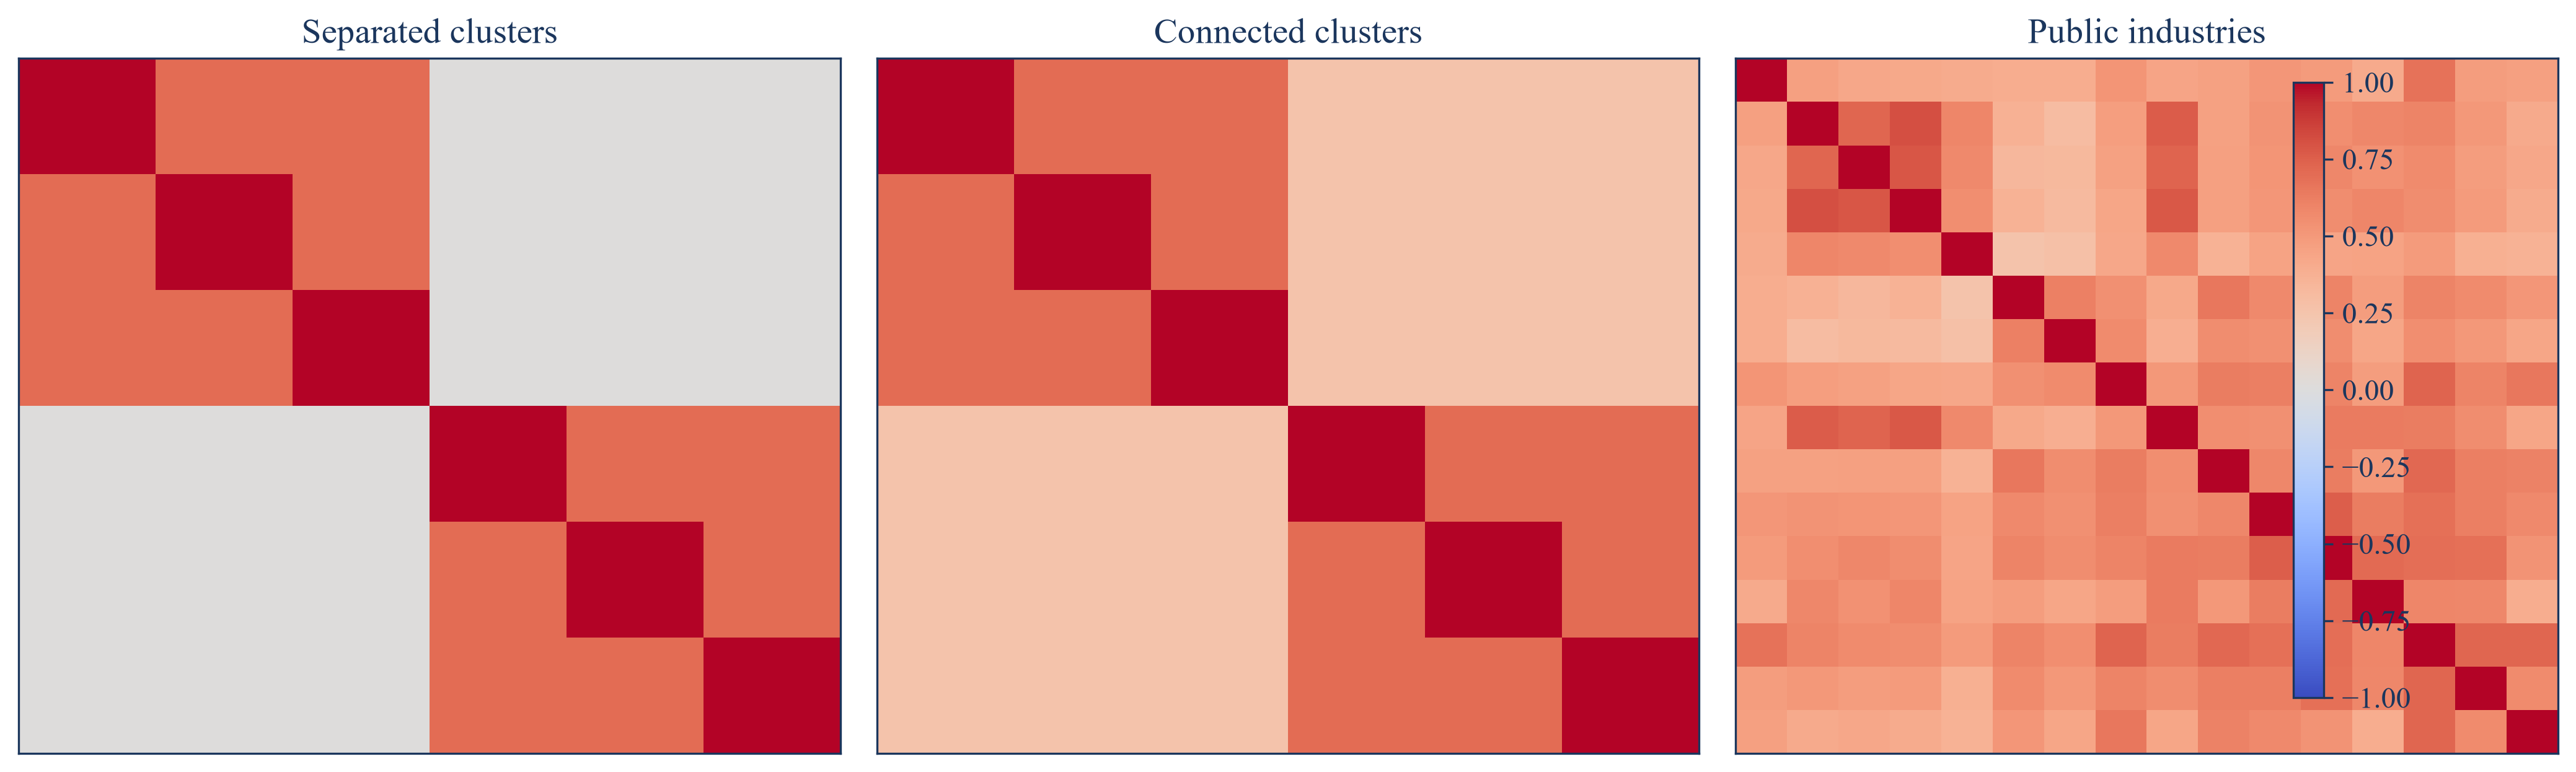

,Cluster,Industries,Mean silhouette value,Minimum silhouette value
0,1,6,0.234747,0.030072
1,2,10,0.16692,0.077726


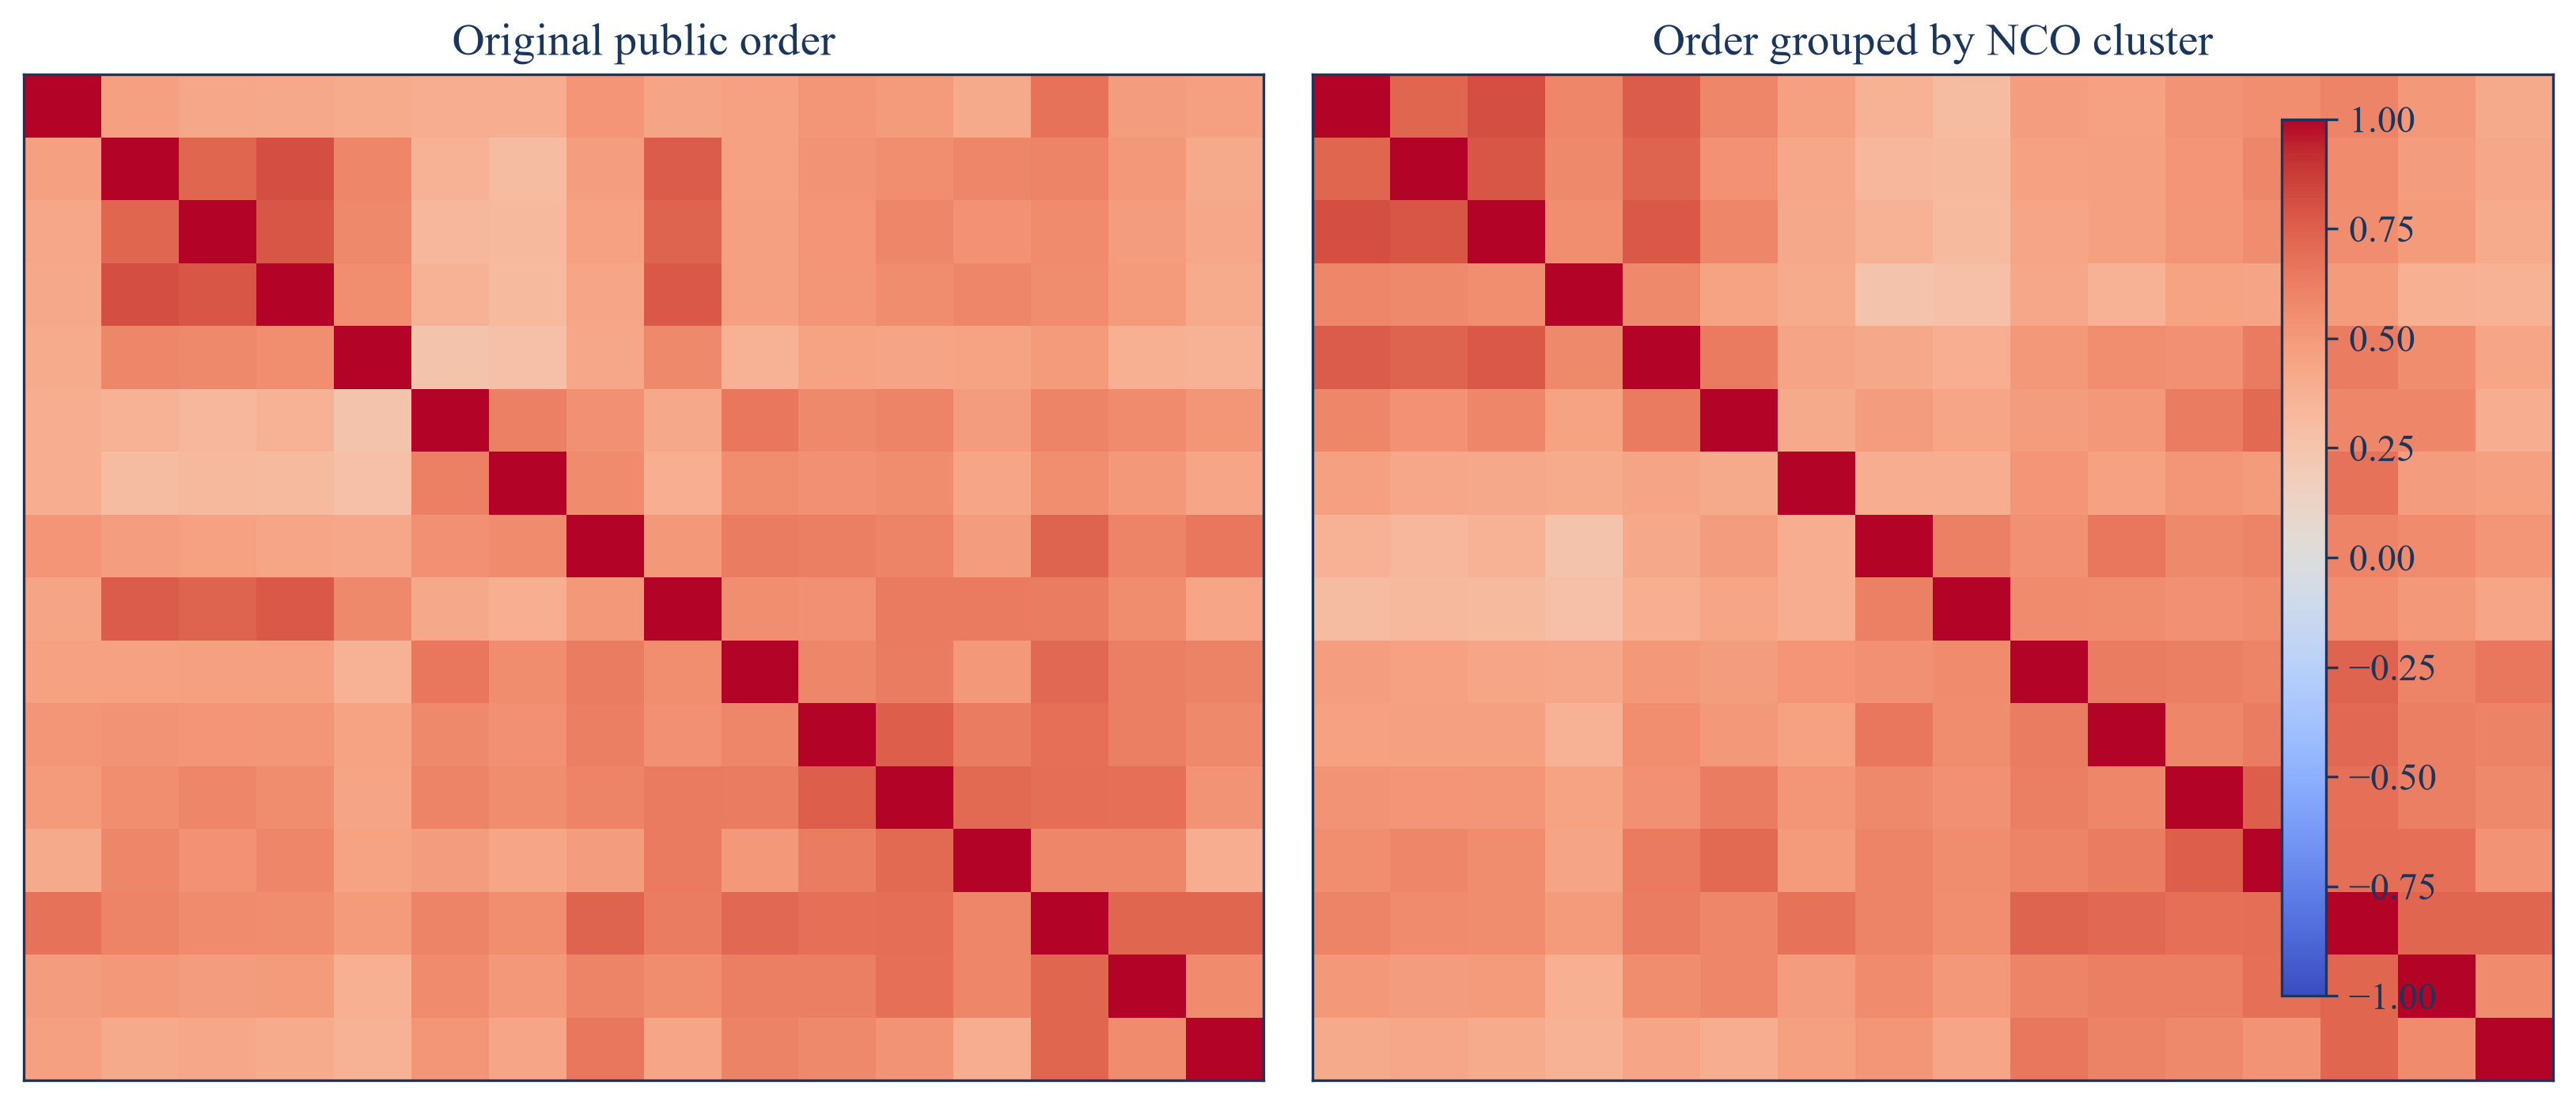

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import time
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.cluster.clustering import cluster_k_means_base, covariance_to_correlation
from RiskLabAI.data.denoise.denoising import denoise_cov
from RiskLabAI.hpc.hpc import parallel_run
from RiskLabAI.optimization.hedging import pca_weights
from RiskLabAI.optimization.hrp import hrp
from RiskLabAI.optimization.nco import get_optimal_portfolio_weights, get_optimal_portfolio_weights_nco

FIGURES = ROOT / "outputs" / "figures" / "26_nested_cluster_optimization"
TABLES = ROOT / "outputs" / "tables" / "26_nested_cluster_optimization"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def correlation_frame(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    values = covariance_to_correlation(frame.to_numpy(dtype=float))
    return pd.DataFrame(values, index=frame.index, columns=frame.columns)

def optimal_series(covariance, mean=None):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    mean_values = None if mean is None else np.asarray(mean, dtype=float).reshape(-1, 1)
    values = get_optimal_portfolio_weights(frame.to_numpy(dtype=float), mean_values).flatten()
    return pd.Series(values, index=frame.index, dtype=float)

def nco_components(covariance, mean=None, maximum_clusters=4, seed=2201):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    correlation = correlation_frame(frame)
    mean_series = None if mean is None else pd.Series(np.asarray(mean, dtype=float).flatten(), index=frame.index)
    np.random.seed(seed)
    sorted_correlation, clusters, silhouette = cluster_k_means_base(correlation, max_clusters=maximum_clusters, iterations=10)
    within = pd.DataFrame(0.0, index=frame.index, columns=sorted(clusters))
    for cluster_id, members in clusters.items():
        local_mean = None if mean_series is None else mean_series.loc[members].to_numpy().reshape(-1, 1)
        within.loc[members, cluster_id] = get_optimal_portfolio_weights(frame.loc[members, members].to_numpy(), local_mean).flatten()
    reduced_covariance = within.T.dot(frame.dot(within))
    reduced_mean = None if mean_series is None else within.T.dot(mean_series).to_numpy().reshape(-1, 1)
    between = pd.Series(get_optimal_portfolio_weights(reduced_covariance.to_numpy(), reduced_mean).flatten(), index=reduced_covariance.index)
    final = within.mul(between, axis=1).sum(axis=1)
    return {"correlation": correlation, "sorted_correlation": sorted_correlation, "clusters": clusters, "silhouette": silhouette, "within": within, "reduced_covariance": reduced_covariance, "between": between, "final": final}

def released_nco(covariance, mean=None, maximum_clusters=4, seed=2201):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    mean_values = None if mean is None else np.asarray(mean, dtype=float).reshape(-1, 1)
    np.random.seed(seed)
    values = get_optimal_portfolio_weights_nco(frame.to_numpy(dtype=float), mean_values, number_clusters=maximum_clusters).flatten()
    return pd.Series(values, index=frame.index, dtype=float)

def inverse_variance_series(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    values = 1.0 / np.diag(frame.to_numpy(dtype=float))
    return pd.Series(values / values.sum(), index=frame.index)

def hrp_series(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    return hrp(frame, correlation_frame(frame)).reindex(frame.index)

def portfolio_variance(weights, covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    vector = pd.Series(weights, index=frame.index).reindex(frame.index).to_numpy(dtype=float)
    return float(vector @ frame.to_numpy(dtype=float) @ vector)

def portfolio_statistics(name, weights, covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    vector = pd.Series(weights, index=frame.index).reindex(frame.index).to_numpy(dtype=float)
    variance = float(vector @ frame.to_numpy(dtype=float) @ vector)
    concentration = float(vector @ vector)
    return {"Portfolio": name, "Annual volatility": float(np.sqrt(variance)), "Net exposure": float(vector.sum()), "Gross exposure": float(np.abs(vector).sum()), "Smallest weight": float(vector.min()), "Largest weight": float(vector.max()), "Effective holdings": float(1.0 / concentration)}

def block_covariance(blocks, block_size, within_correlation, between_correlation=0.03):
    asset_count = blocks * block_size
    correlation = np.full((asset_count, asset_count), between_correlation, dtype=float)
    for block in range(blocks):
        start = block * block_size
        stop = start + block_size
        correlation[start:stop, start:stop] = within_correlation
    np.fill_diagonal(correlation, 1.0)
    scales = np.linspace(0.10, 0.22, asset_count)
    covariance = correlation * np.outer(scales, scales)
    labels = [f"Asset {index + 1}" for index in range(asset_count)]
    return pd.DataFrame(covariance, index=labels, columns=labels), pd.DataFrame(correlation, index=labels, columns=labels)

def one_way_turnover(current, previous):
    current_values = pd.Series(current).sort_index().to_numpy(dtype=float)
    previous_values = pd.Series(previous).sort_index().to_numpy(dtype=float)
    return float(0.5 * np.abs(current_values - previous_values).sum())

display_industry_names = {"Agric": "Agriculture", "Food": "Food products", "Soda": "Soft drinks", "Beer": "Beer and liquor", "Smoke": "Tobacco", "Toys": "Recreation", "Fun": "Entertainment", "Books": "Printing and publishing", "Hshld": "Household products", "Clths": "Apparel", "Hlth": "Health care", "MedEq": "Medical equipment", "Drugs": "Pharmaceutical products", "Chems": "Chemicals", "Rubbr": "Rubber and plastic products", "Txtls": "Textiles"}
selected_assets = list(industry_returns.columns[:16])
public_sample = industry_returns[selected_assets].rename(columns=display_industry_names).copy()
public_covariance = public_sample.cov() * 252.0
public_correlation = public_sample.corr()
public_provenance = pd.DataFrame({"Field": ["Provider", "Return type", "Analysis start", "Analysis end", "Complete dates", "Selected industries", "Selection rule"], "Value": ["Kenneth R. French Data Library", "Daily value-weighted return", str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(selected_assets), "First 16 industries in archive order, fixed before analysis"]})

save_table(public_provenance, "nco_data_provenance", "Public data used for the Chapter 22 NCO calculation.", "tab:chapter22-nco-data")
display(public_provenance)

separated_covariance, separated_correlation = block_covariance(2, 3, 0.70, 0.00)
connected_covariance, connected_correlation = block_covariance(2, 3, 0.70, 0.25)
condition_rows = []
for name, covariance, correlation in [("Separated clusters", separated_covariance, separated_correlation), ("Connected clusters", connected_covariance, connected_correlation), ("Public industries", public_covariance, public_correlation)]:
    eigenvalues = np.linalg.eigvalsh(covariance.to_numpy(dtype=float))
    condition_rows.append({"Case": name, "Assets": len(covariance), "Smallest eigenvalue": eigenvalues.min(), "Largest eigenvalue": eigenvalues.max(), "Condition number": eigenvalues.max() / eigenvalues.min(), "Mean off-diagonal correlation": float((correlation.to_numpy().sum() - len(correlation)) / (len(correlation) * (len(correlation) - 1)))})
condition_summary = pd.DataFrame(condition_rows)
save_table(condition_summary, "condition_number_cases", "Condition numbers for two controlled covariance structures and the public sample.", "tab:chapter22-condition-cases")
display(condition_summary)

figure, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for axis, matrix, title in zip(axes, [separated_correlation, connected_correlation, public_correlation], ["Separated clusters", "Connected clusters", "Public industries"]):
    image = axis.imshow(matrix.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(image, ax=axes, fraction=0.018, pad=0.02)
figure.tight_layout()
save_figure(figure, "condition_number_correlation_cases")

public_components = nco_components(public_covariance, maximum_clusters=4, seed=2201)
cluster_rows = []
for cluster_id, members in public_components["clusters"].items():
    for member in members:
        cluster_rows.append({"Cluster": int(cluster_id) + 1, "Industry": member, "Silhouette value": public_components["silhouette"].loc[member]})
cluster_membership = pd.DataFrame(cluster_rows).sort_values(["Cluster", "Industry"]).reset_index(drop=True)
cluster_summary = cluster_membership.groupby("Cluster", as_index=False).agg(**{"Industries": ("Industry", "count"), "Mean silhouette value": ("Silhouette value", "mean"), "Minimum silhouette value": ("Silhouette value", "min")})
save_table(cluster_membership, "public_cluster_membership", "Deterministic public-industry cluster membership.", "tab:chapter22-cluster-membership")
save_table(cluster_summary, "public_cluster_summary", "Public-industry cluster sizes and silhouette values.", "tab:chapter22-cluster-summary")
display(cluster_summary)

ordered_assets = [asset for cluster_id in sorted(public_components["clusters"]) for asset in public_components["clusters"][cluster_id]]
ordered_correlation = public_correlation.loc[ordered_assets, ordered_assets]
figure, axes = plt.subplots(1, 2, figsize=(11, 4.8))
first = axes[0].imshow(public_correlation.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
axes[0].set_title("Original public order")
axes[1].imshow(ordered_correlation.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
axes[1].set_title("Order grouped by NCO cluster")
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(first, ax=axes, fraction=0.025, pad=0.02)
figure.tight_layout()
save_figure(figure, "public_nco_cluster_structure")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Within-Cluster Portfolios

Within cluster $g$, the fully invested optimization direction is normalized to give local weights:

$$
v_g=\frac{\Sigma_{gg}^{-1}m_g}{\mathbf 1_g^{\mathsf T}\Sigma_{gg}^{-1}m_g}.
$$

Here, $g$ labels a cluster, $\Sigma_{gg}$ is its covariance block, $m_g$ is a vector of ones for minimum variance or a vector of expected returns for a return-directed portfolio, $\mathbf 1_g$ is a vector of ones, and $v_g$ is the cluster's local weight vector.

,Cluster,Industries,Weight sum,Smallest weight,Largest weight,Cluster variance
0,1,6,1,-0.181577,0.506141,0.023268
1,2,10,1,-0.141539,0.354479,0.038308


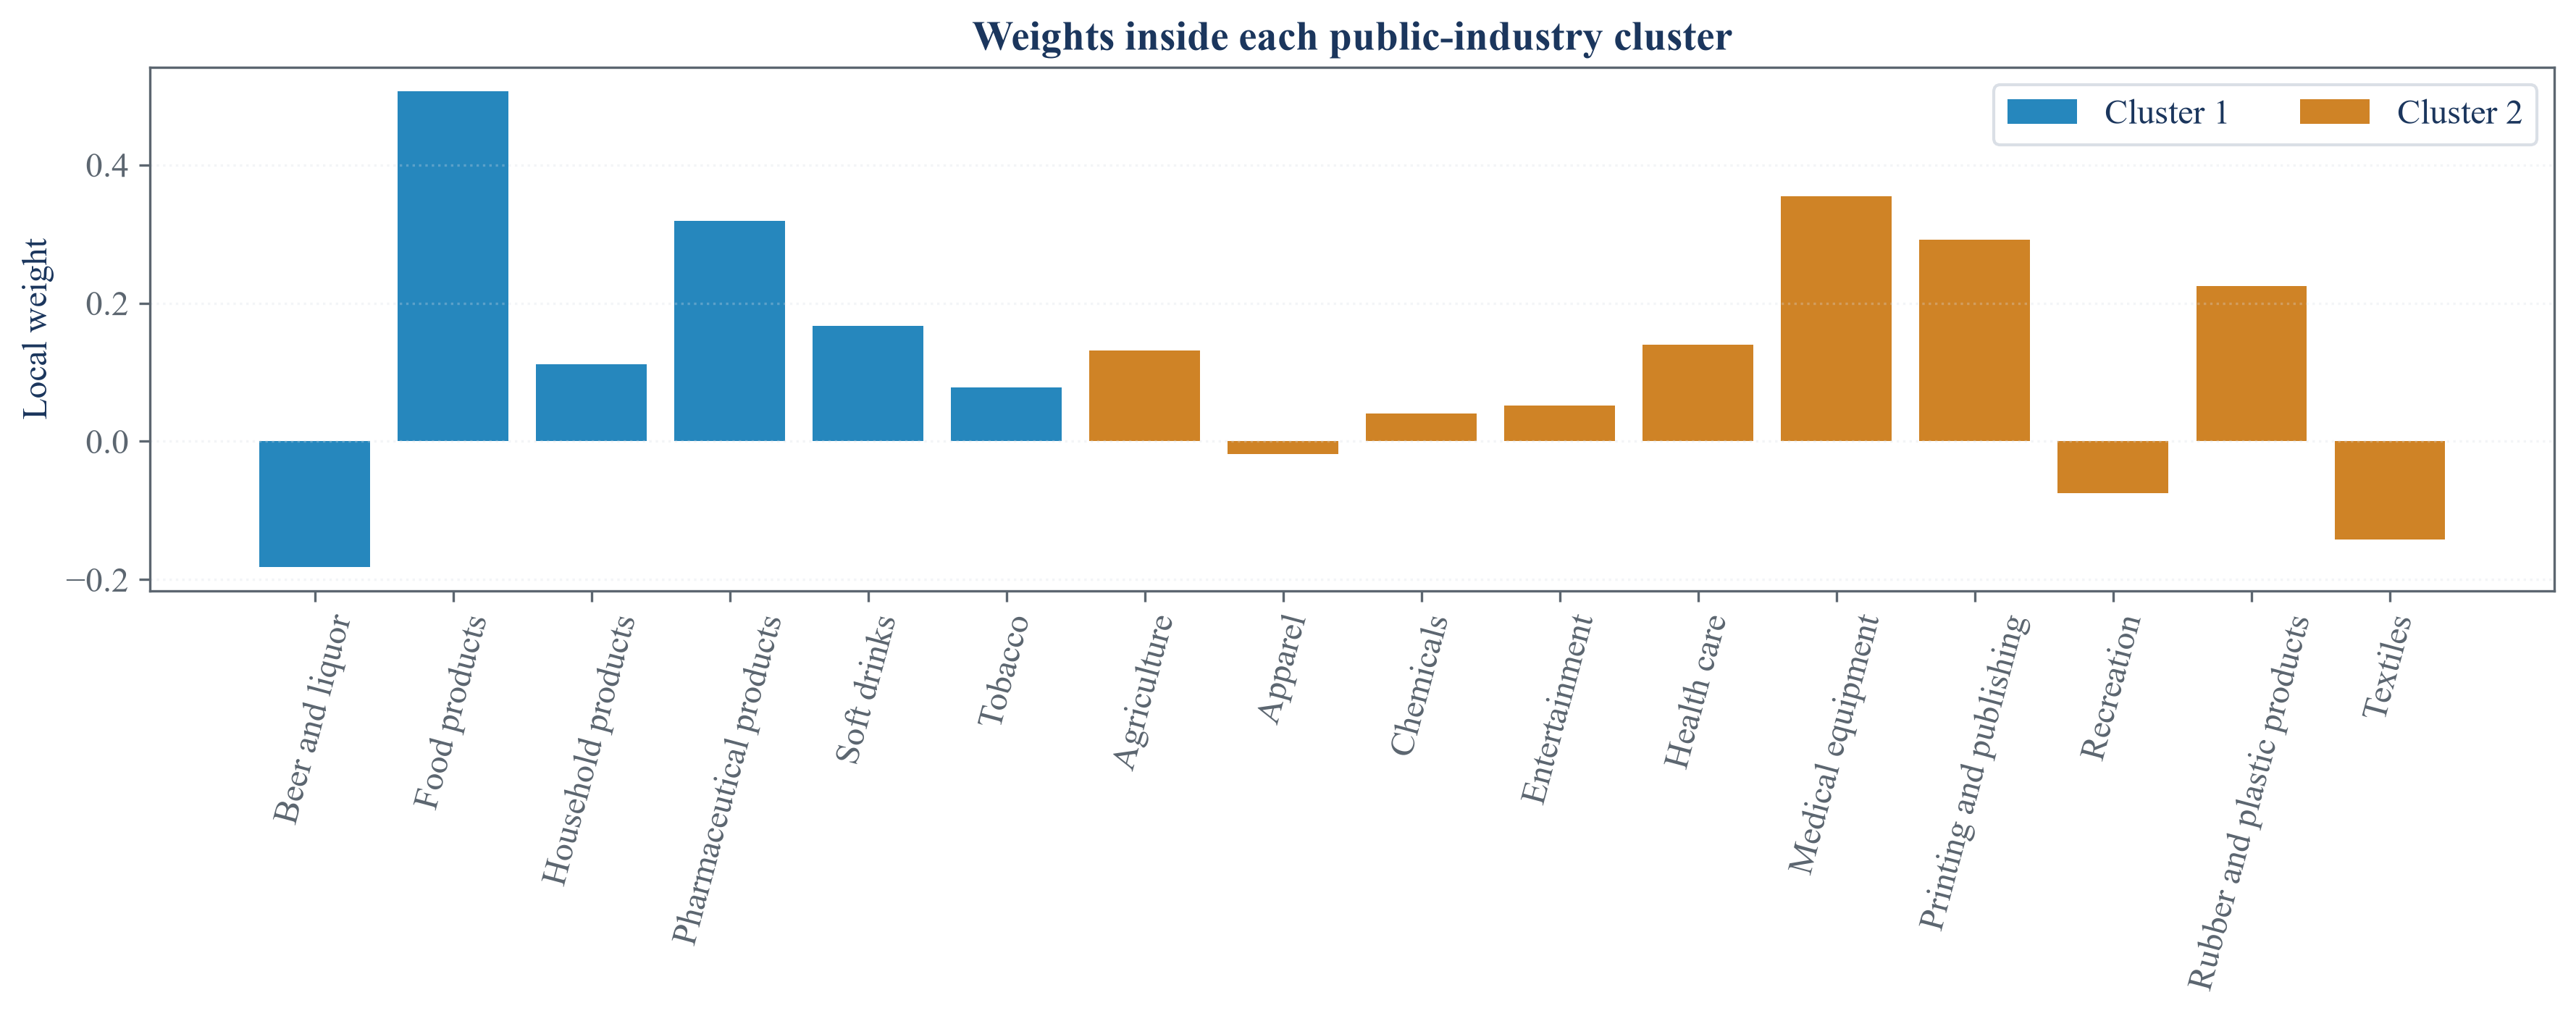

In [2]:
within_rows = []
for cluster_id in public_components["within"].columns:
    members = public_components["clusters"][cluster_id]
    local_covariance = public_covariance.loc[members, members]
    local_weights = public_components["within"].loc[members, cluster_id]
    local_variance = portfolio_variance(local_weights, local_covariance)
    for member in members:
        within_rows.append({"Cluster": int(cluster_id) + 1, "Industry": member, "Within-cluster weight": local_weights.loc[member], "Cluster variance": local_variance})
within_weights = pd.DataFrame(within_rows).sort_values(["Cluster", "Industry"]).reset_index(drop=True)
within_checks = within_weights.groupby("Cluster", as_index=False).agg(**{"Industries": ("Industry", "count"), "Weight sum": ("Within-cluster weight", "sum"), "Smallest weight": ("Within-cluster weight", "min"), "Largest weight": ("Within-cluster weight", "max"), "Cluster variance": ("Cluster variance", "first")})
save_table(within_weights, "within_cluster_weights", "Public within-cluster minimum-variance weights.", "tab:chapter22-within-weights")
save_table(within_checks, "within_cluster_checks", "Within-cluster normalization and risk checks.", "tab:chapter22-within-checks")
display(within_checks)

figure, axis = plt.subplots(figsize=(12, 4.8))
colors = [palette["cyan"], palette["amber"], palette["green"], palette["violet"]]
for cluster_id, subset in within_weights.groupby("Cluster"):
    axis.bar(subset["Industry"], subset["Within-cluster weight"], label=f"Cluster {cluster_id}", color=colors[(cluster_id - 1) % len(colors)], alpha=0.85)
axis.set_title("Weights inside each public-industry cluster")
axis.set_ylabel("Local weight")
axis.tick_params(axis="x", rotation=75)
axis.grid(axis="y", alpha=0.3)
axis.legend(ncols=2)
figure.tight_layout()
save_figure(figure, "within_cluster_weight_profiles")

## The Reduced Cluster Problem

Placing the local cluster portfolios in the columns of $B$ reduces the asset covariance matrix to a cluster covariance matrix:

$$
\Sigma_C=B^{\mathsf T}\Sigma B.
$$

Here, $B$ is the matrix of within-cluster weights with zeros outside each cluster, $\Sigma$ is the full asset covariance matrix, and $\Sigma_C$ is the covariance matrix of the cluster portfolios.

,Cluster portfolio,Cluster 1,Cluster 2
0,Cluster 1,0.023268,0.021898
1,Cluster 2,0.021898,0.038308


,Quantity,Value
0,Asset covariance dimension,16
1,Reduced covariance dimension,2
2,Asset condition number,103.308892
3,Reduced condition number,7.065207
4,Smallest reduced eigenvalue,0.007635
5,Largest reduced eigenvalue,0.053941


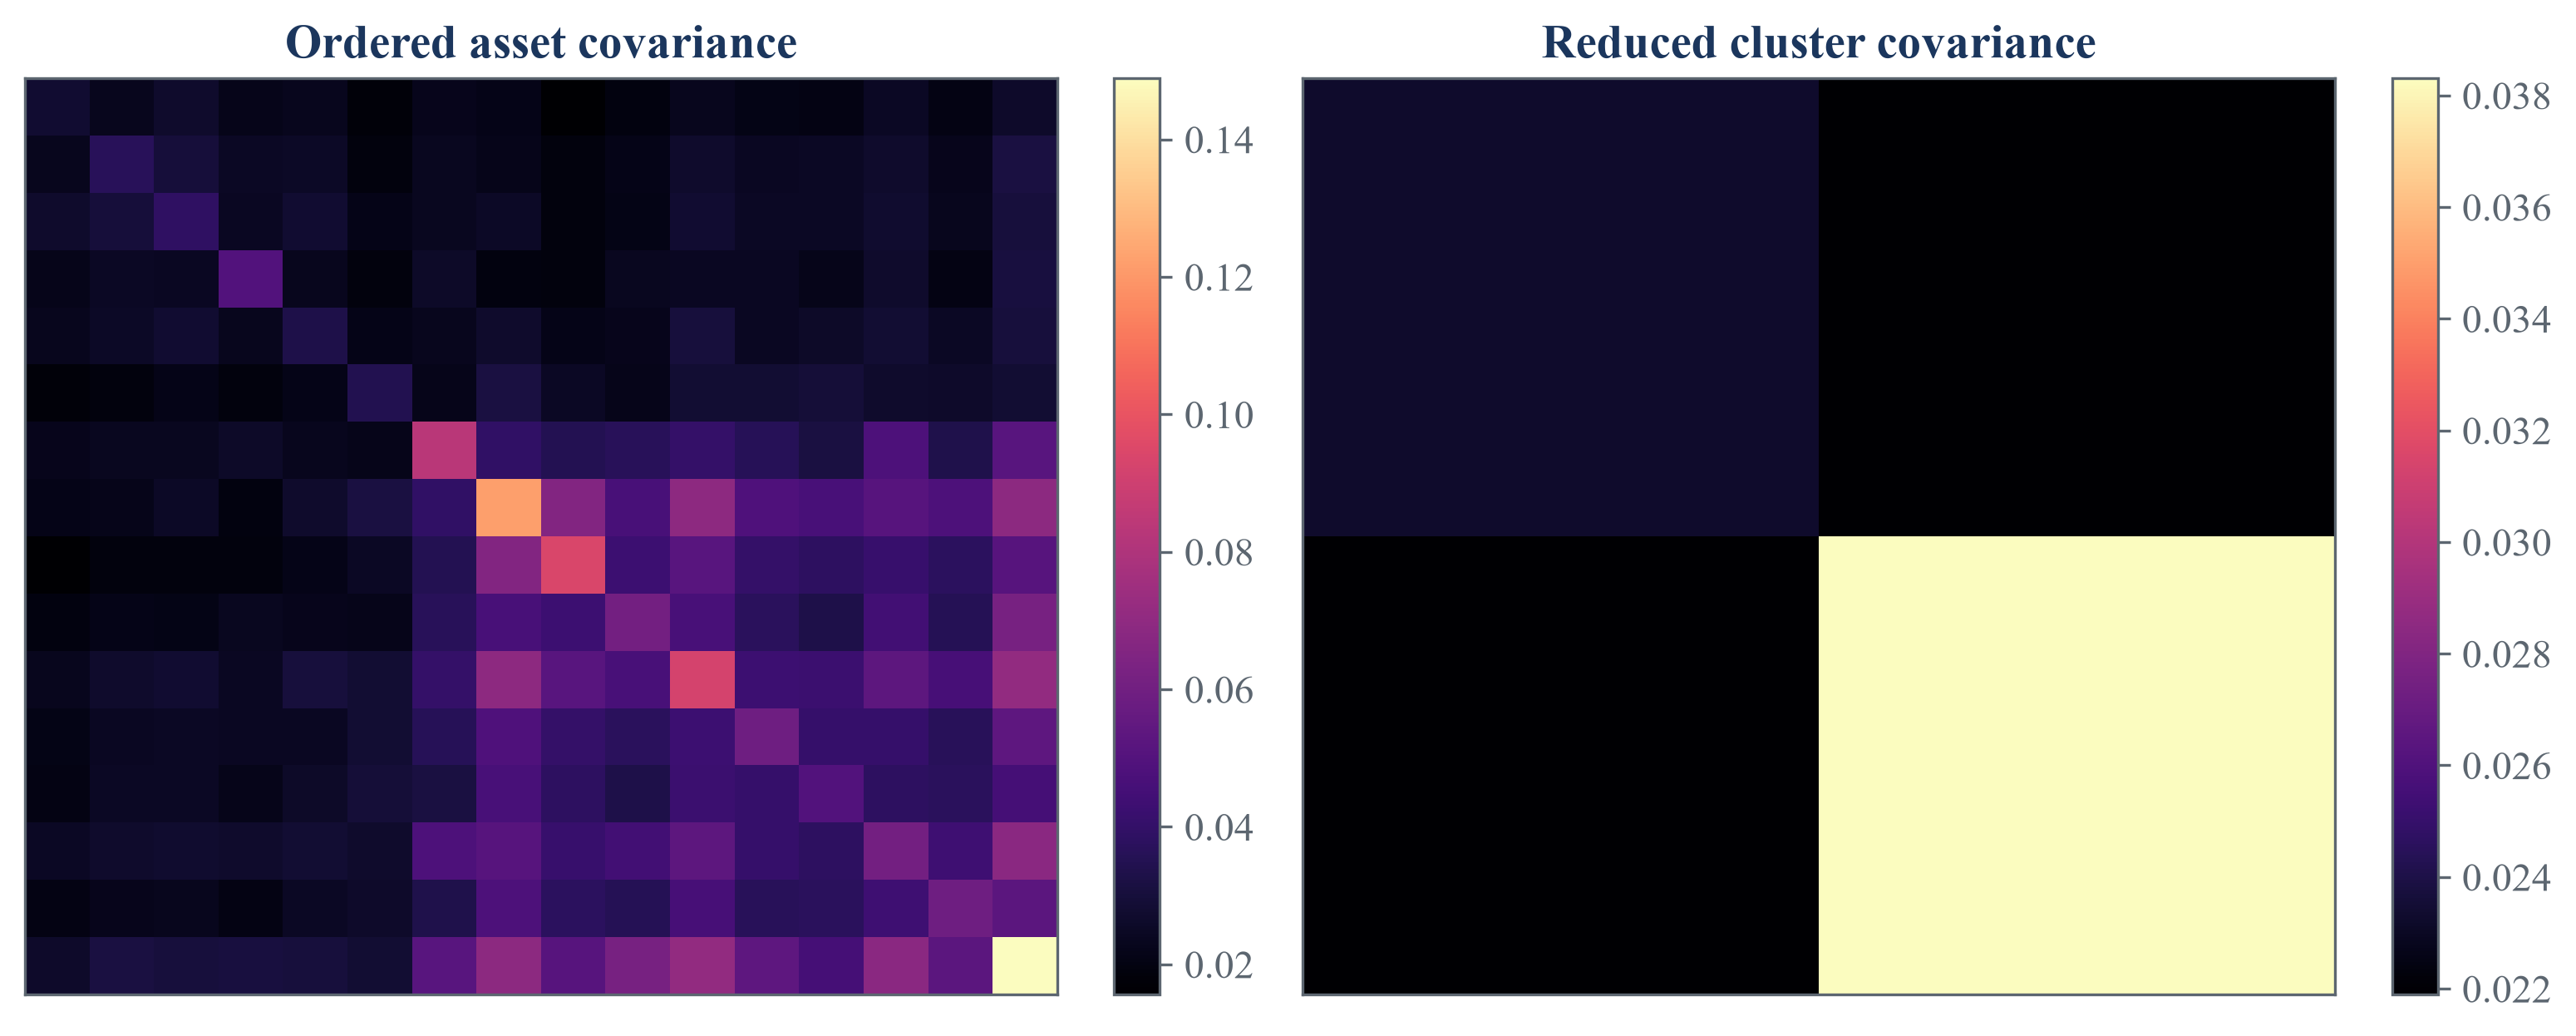

In [3]:
reduced_covariance = public_components["reduced_covariance"].copy()
reduced_covariance.index = [f"Cluster {int(value) + 1}" for value in reduced_covariance.index]
reduced_covariance.columns = [f"Cluster {int(value) + 1}" for value in reduced_covariance.columns]
reduced_table = reduced_covariance.reset_index().rename(columns={"index": "Cluster portfolio"})
reduced_eigenvalues = np.linalg.eigvalsh(reduced_covariance.to_numpy(dtype=float))
reduced_summary = pd.DataFrame({"Quantity": ["Asset covariance dimension", "Reduced covariance dimension", "Asset condition number", "Reduced condition number", "Smallest reduced eigenvalue", "Largest reduced eigenvalue"], "Value": [len(public_covariance), len(reduced_covariance), np.linalg.cond(public_covariance.to_numpy(dtype=float)), np.linalg.cond(reduced_covariance.to_numpy(dtype=float)), reduced_eigenvalues.min(), reduced_eigenvalues.max()]})
save_table(reduced_table, "reduced_cluster_covariance", "Covariance matrix of the public cluster portfolios.", "tab:chapter22-reduced-covariance")
save_table(reduced_summary, "reduced_problem_summary", "Dimensions and condition numbers before and after reduction.", "tab:chapter22-reduced-summary")
display(reduced_table)
display(reduced_summary)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
asset_image = axes[0].imshow(public_covariance.loc[ordered_assets, ordered_assets].to_numpy(dtype=float), cmap="magma", aspect="auto")
axes[0].set_title("Ordered asset covariance")
cluster_image = axes[1].imshow(reduced_covariance.to_numpy(dtype=float), cmap="magma", aspect="auto")
axes[1].set_title("Reduced cluster covariance")
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(asset_image, ax=axes[0], fraction=0.046)
figure.colorbar(cluster_image, ax=axes[1], fraction=0.046)
figure.tight_layout()
save_figure(figure, "asset_and_reduced_covariance")

## Recombining cluster portfolios

The cluster portfolios are optimized and then mapped back to the original assets:

$$
a=\frac{\Sigma_C^{-1}m_C}{\mathbf 1_C^{\mathsf T}\Sigma_C^{-1}m_C},
\qquad
w^{\mathrm{NCO}}=Ba.
$$

Here, $a$ contains between-cluster weights, $m_C=B^{\mathsf T}m$ is the reduced return direction or a vector of ones in the minimum-variance case, $\mathbf 1_C$ is a vector of ones over clusters, and $w^{\mathrm{NCO}}$ contains the final asset weights.

,Cluster,Between-cluster weight
0,Cluster 1,0.922945
1,Cluster 2,0.077055


,Industry,NCO weight,Cluster
0,Agriculture,0.01014,2
1,Apparel,-0.00139,2
2,Beer and liquor,-0.167586,1
3,Chemicals,0.003142,2
4,Entertainment,0.003989,2
5,Food products,0.46714,1
6,Health care,0.010781,2
7,Household products,0.1028,1
8,Medical equipment,0.027314,2
9,Pharmaceutical products,0.294033,1


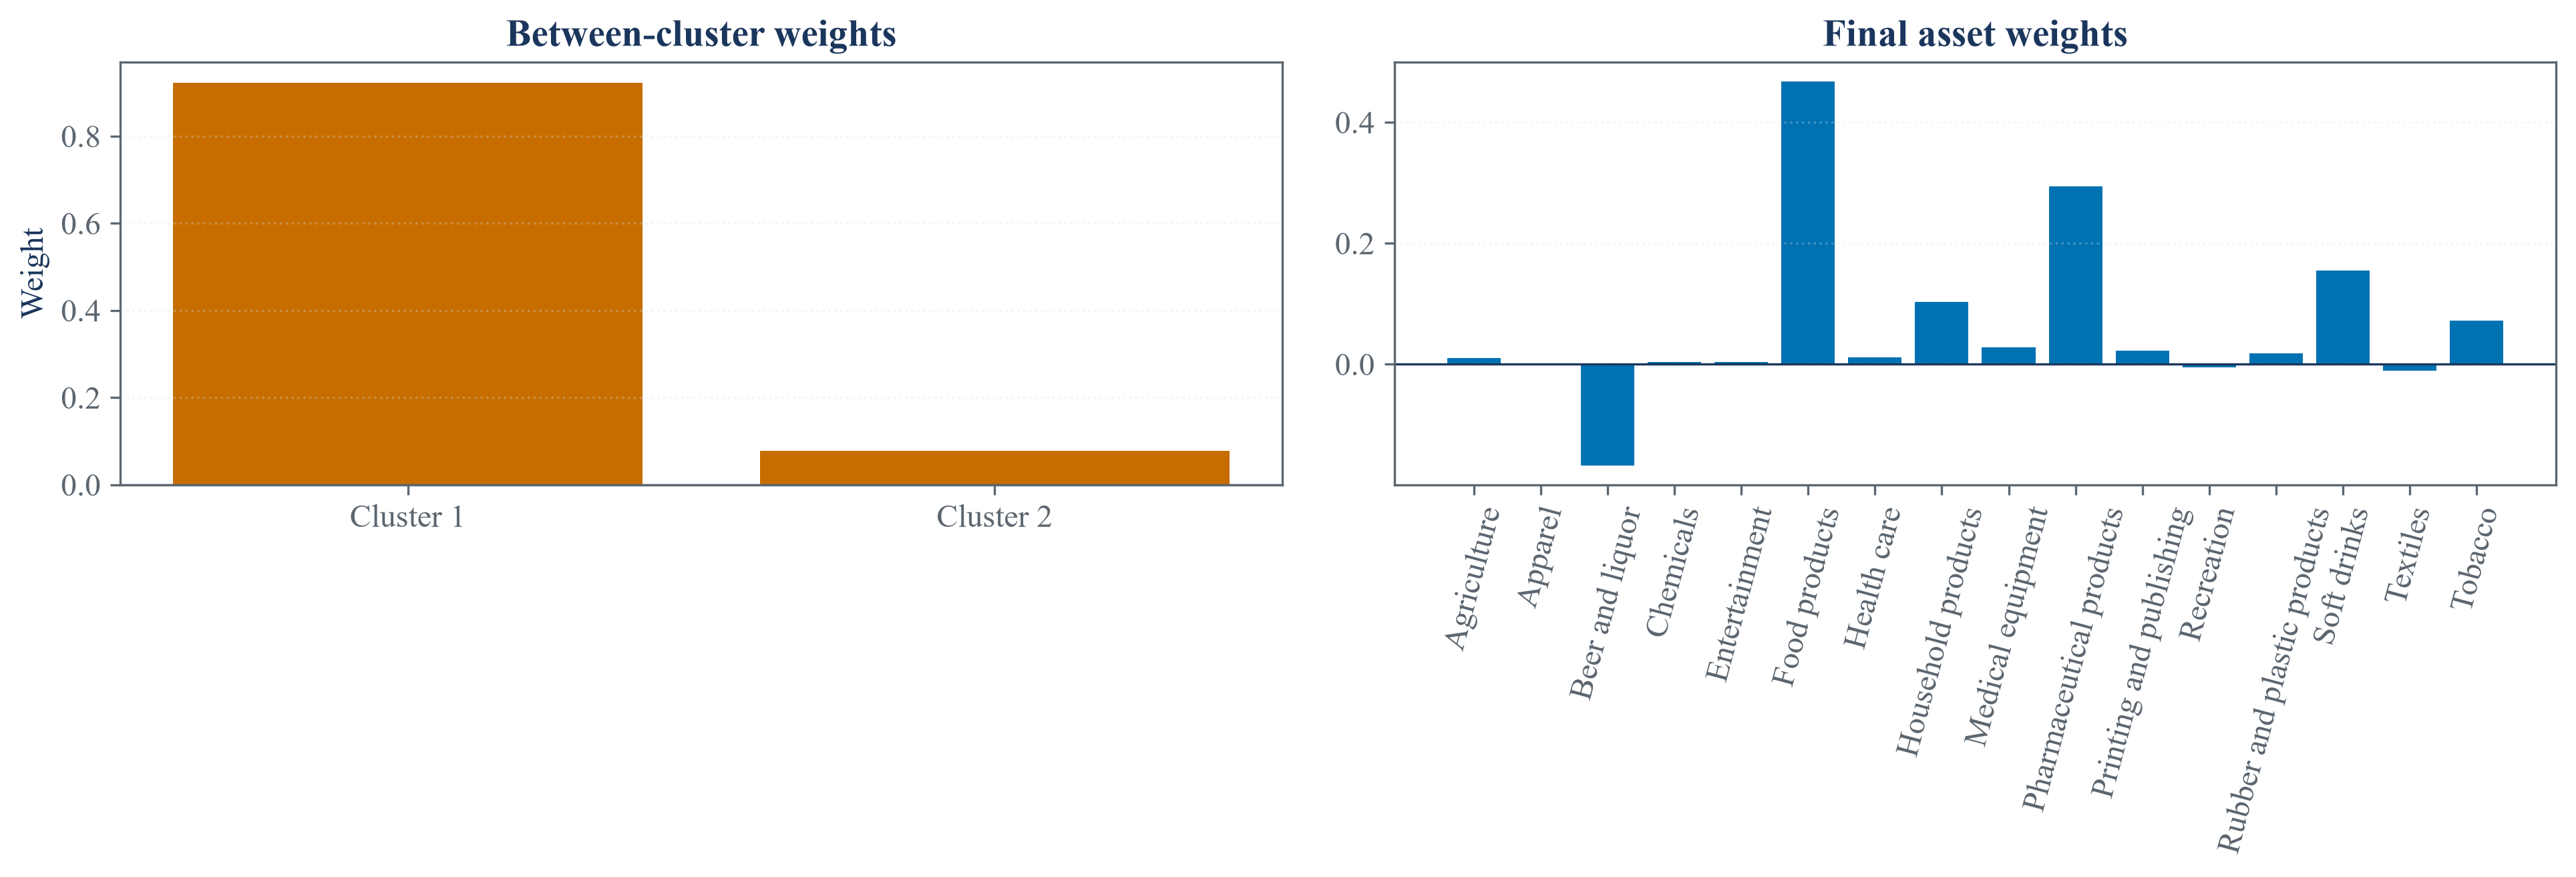

In [4]:
between_weights = public_components["between"].copy()
between_table = pd.DataFrame({"Cluster": [f"Cluster {int(value) + 1}" for value in between_weights.index], "Between-cluster weight": between_weights.to_numpy(dtype=float)})
final_weights = public_components["final"].sort_index()
final_table = pd.DataFrame({"Industry": final_weights.index, "NCO weight": final_weights.to_numpy(dtype=float), "Cluster": [int(next(cluster_id for cluster_id, members in public_components["clusters"].items() if asset in members)) + 1 for asset in final_weights.index]})
save_table(between_table, "between_cluster_weights", "Weights assigned to the public cluster portfolios.", "tab:chapter22-between-weights")
save_table(final_table, "public_nco_weights", "Final public-industry NCO weights.", "tab:chapter22-public-nco-weights")
display(between_table)
display(final_table)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(between_table["Cluster"], between_table["Between-cluster weight"], color=palette["amber"])
axes[0].set_title("Between-cluster weights")
axes[0].set_ylabel("Weight")
axes[1].bar(final_table["Industry"], final_table["NCO weight"], color=palette["cyan"])
axes[1].set_title("Final asset weights")
axes[1].tick_params(axis="x", rotation=75)
for axis in axes:
    axis.axhline(0.0, color=palette["text"], linewidth=0.8)
    axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "between_and_final_nco_weights")

## Released Calculation Checks

The reduced covariance preserves the variance of every weight vector formed from the cluster portfolios:

$$
(Ba)^{\mathsf T}\Sigma(Ba)=a^{\mathsf T}(B^{\mathsf T}\Sigma B)a=a^{\mathsf T}\Sigma_Ca.
$$

Here, $B$ contains within-cluster weights, $a$ contains between-cluster weights, $\Sigma$ is the full covariance matrix, and $\Sigma_C$ is the reduced covariance matrix.

In [5]:
released_weights = released_nco(public_covariance, maximum_clusters=4, seed=2201)
direct_variance = portfolio_variance(public_components["final"], public_covariance)
reduced_vector = public_components["between"].to_numpy(dtype=float)
reduced_variance = float(reduced_vector @ public_components["reduced_covariance"].to_numpy(dtype=float) @ reduced_vector)
comparison = pd.DataFrame({"Industry": public_covariance.index, "Direct two-stage weight": public_components["final"].reindex(public_covariance.index).to_numpy(dtype=float), "Library NCO weight": released_weights.reindex(public_covariance.index).to_numpy(dtype=float)})
comparison["Absolute difference"] = np.abs(comparison["Direct two-stage weight"] - comparison["Library NCO weight"])
calculation_checks = pd.DataFrame({"Check": ["Directly assembled weights sum to one", "Library weights sum to one", "Largest direct and library weight difference", "Full variance", "Reduced variance", "Absolute variance difference"], "Value": [public_components["final"].sum(), released_weights.sum(), comparison["Absolute difference"].max(), direct_variance, reduced_variance, abs(direct_variance - reduced_variance)]})
public_portfolio_summary = pd.DataFrame([portfolio_statistics("NCO", released_weights, public_covariance), portfolio_statistics("Ordinary minimum variance", optimal_series(public_covariance), public_covariance), portfolio_statistics("Inverse variance", inverse_variance_series(public_covariance), public_covariance), portfolio_statistics("Equal weight", pd.Series(1.0 / len(public_covariance), index=public_covariance.index), public_covariance)])
public_portfolio_book_summary = public_portfolio_summary[["Portfolio", "Annual volatility", "Net exposure", "Gross exposure", "Smallest weight", "Largest weight"]]
section_summary = pd.DataFrame({"Quantity": ["Public observations", "Selected industries", "Detected clusters", "Within-cluster portfolios", "Reduced covariance dimension", "Final weights"], "Value": [len(public_sample), len(selected_assets), len(public_components["clusters"]), len(public_components["clusters"]), len(public_components["reduced_covariance"]), len(public_components["final"])]})
save_table(comparison, "released_nco_weight_check", "Directly assembled and library NCO weights for the public covariance matrix.", "tab:chapter22-released-nco-check")
save_table(calculation_checks, "nco_calculation_checks", "Direct checks of the two-stage NCO calculation.", "tab:chapter22-calculation-checks")
save_table(public_portfolio_book_summary, "public_nco_portfolio_summary", "Public-sample fitted portfolio summaries.", "tab:chapter22-public-portfolio-summary")
save_table(section_summary, "nco_section_summary", "Section 22.1 numerical summary.", "tab:chapter22-nco-section-summary")
display(calculation_checks)
display(public_portfolio_summary)
display(section_summary)

,Check,Value
0,Directly assembled weights sum to one,1
1,Library weights sum to one,1
2,Largest direct and library weight difference,0
3,Full variance,0.023162
4,Reduced variance,0.023162
5,Absolute variance difference,0


,Portfolio,Annual volatility,Net exposure,Gross exposure,Smallest weight,Largest weight,Effective holdings
0,NCO,0.152192,1,1.371259,-0.167586,0.46714,2.671549
1,Ordinary minimum variance,0.147925,1,1.958914,-0.167604,0.489942,2.114899
2,Inverse variance,0.169625,1,1,0.022161,0.118033,13.435053
3,Equal weight,0.185824,1,1,0.0625,0.0625,16


,Quantity,Value
0,Public observations,1760
1,Selected industries,16
2,Detected clusters,2
3,Within-cluster portfolios,2
4,Reduced covariance dimension,2
5,Final weights,16


## Tests

In [6]:
assert data_hash == EXPECTED_DATA_HASH
assert public_sample.shape == (1760, 16)
assert np.all(np.linalg.eigvalsh(separated_covariance.to_numpy(dtype=float)) > 0.0)
assert np.all(np.linalg.eigvalsh(connected_covariance.to_numpy(dtype=float)) > 0.0)
assert len(condition_summary) == 3
assert condition_summary["Condition number"].gt(1.0).all()
assert 2 <= len(public_components["clusters"]) <= 4
assert sorted(cluster_membership["Industry"].tolist()) == sorted(public_sample.columns)
assert cluster_membership["Silhouette value"].between(-1.0, 1.0).all()
assert np.allclose(within_checks["Weight sum"], 1.0)
assert public_components["within"].shape == (16, len(public_components["clusters"]))
assert public_components["reduced_covariance"].shape == (len(public_components["clusters"]), len(public_components["clusters"]))
assert np.allclose(public_components["reduced_covariance"], public_components["reduced_covariance"].T)
assert np.linalg.eigvalsh(public_components["reduced_covariance"].to_numpy(dtype=float)).min() > 0.0
assert np.isclose(public_components["between"].sum(), 1.0)
assert np.isclose(public_components["final"].sum(), 1.0)
assert np.isclose(released_weights.sum(), 1.0)
assert comparison["Absolute difference"].max() < 1e-12
assert abs(direct_variance - reduced_variance) < 1e-12
assert len(public_portfolio_summary) == 4
assert public_portfolio_summary["Annual volatility"].gt(0.0).all()
assert len(section_summary) == 6
assert (FIGURES / "condition_number_correlation_cases.pdf").is_file()
assert (FIGURES / "public_nco_cluster_structure.pdf").is_file()
assert (FIGURES / "within_cluster_weight_profiles.pdf").is_file()
assert (FIGURES / "asset_and_reduced_covariance.pdf").is_file()
assert (FIGURES / "between_and_final_nco_weights.pdf").is_file()
assert (TABLES / "released_nco_weight_check.tex").is_file()
assert (TABLES / "public_nco_portfolio_summary.tex").is_file()